In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf

2026-05-04 17:51:41.365802: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import numpy as np
import pandas as pd

In [3]:
tf.random.set_seed(42)

# Implementing MLPs with Keras
## Building an Image Classifier Using the Sequential API

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_val, y_val = X_train_full[-5000:], y_train_full[-5000:]

In [4]:
X_train.shape

(55000, 28, 28)

In [5]:
X_train.dtype

dtype('uint8')

In [6]:
# Scale the value to range from 0 to 1
X_train, X_val, X_test = X_train/255, X_val/255, X_test/255

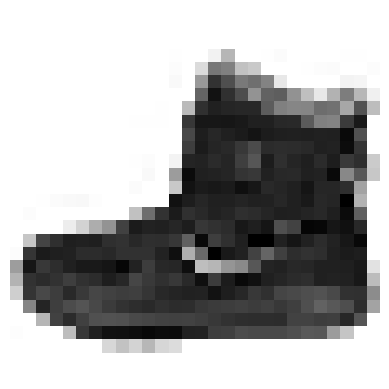

In [7]:
plt.imshow(X_train[0],cmap="binary")
plt.axis("off")
plt.show()

In [8]:
y_train

array([9, 0, 0, ..., 9, 0, 2], shape=(55000,), dtype=uint8)

In [9]:
# The corresponding class names for above integer representation
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

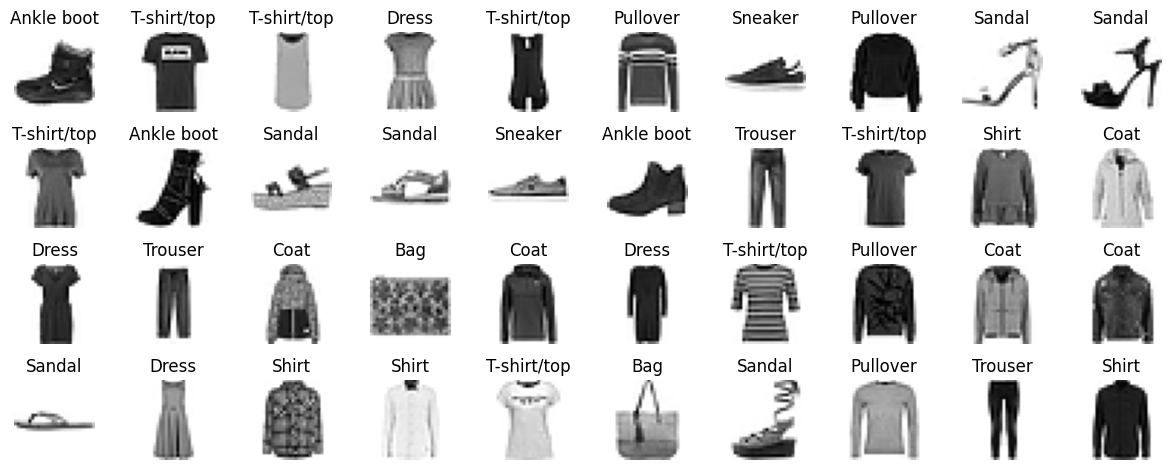

In [10]:
n_rows = 4
n_cols = 10
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
for row in range(n_rows):
    for col in range(n_cols):
        index= n_cols* row + col
        plt.subplot(n_rows,n_cols,index+1)
        plt.imshow(X_train[index],cmap="binary")
        plt.axis("off")
        plt.title(class_names[y_train[index]])
plt.tight_layout()
plt.show()

### Creating the model using the Sequential API

In [11]:
model = tf.keras.Sequential() # create a sequential model
model.add(tf.keras.layers.InputLayer(shape=(28,28))) # create a 1st layer(Input layer) and add to model.If you do not specify the input shape,Keras will simply wait until it knows the input shape before it actually builds the model parameters. In this we are not specified batch size.
model.add(tf.keras.layers.Flatten()) # It convert each input image into 1D array. If it receives image with batch size (32,28,28) it converts (32, 784). 
# It doen't do any calculations, it just converts.
model.add(tf.keras.layers.Dense(300,activation="relu")) # add dense layer with 300 neurons
model.add(tf.keras.layers.Dense(100,activation="relu"))
model.add(tf.keras.layers.Dense(10,activation="softmax")) # output layer for 10 classes

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
## Instead of adding layer one by one , we can pass as a list
# first clear the session to reset the name counters
tf.keras.backend.clear_session()
tf.random.set_seed(42)

# now build model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300,activation="relu"),
    tf.keras.layers.Dense(100,activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

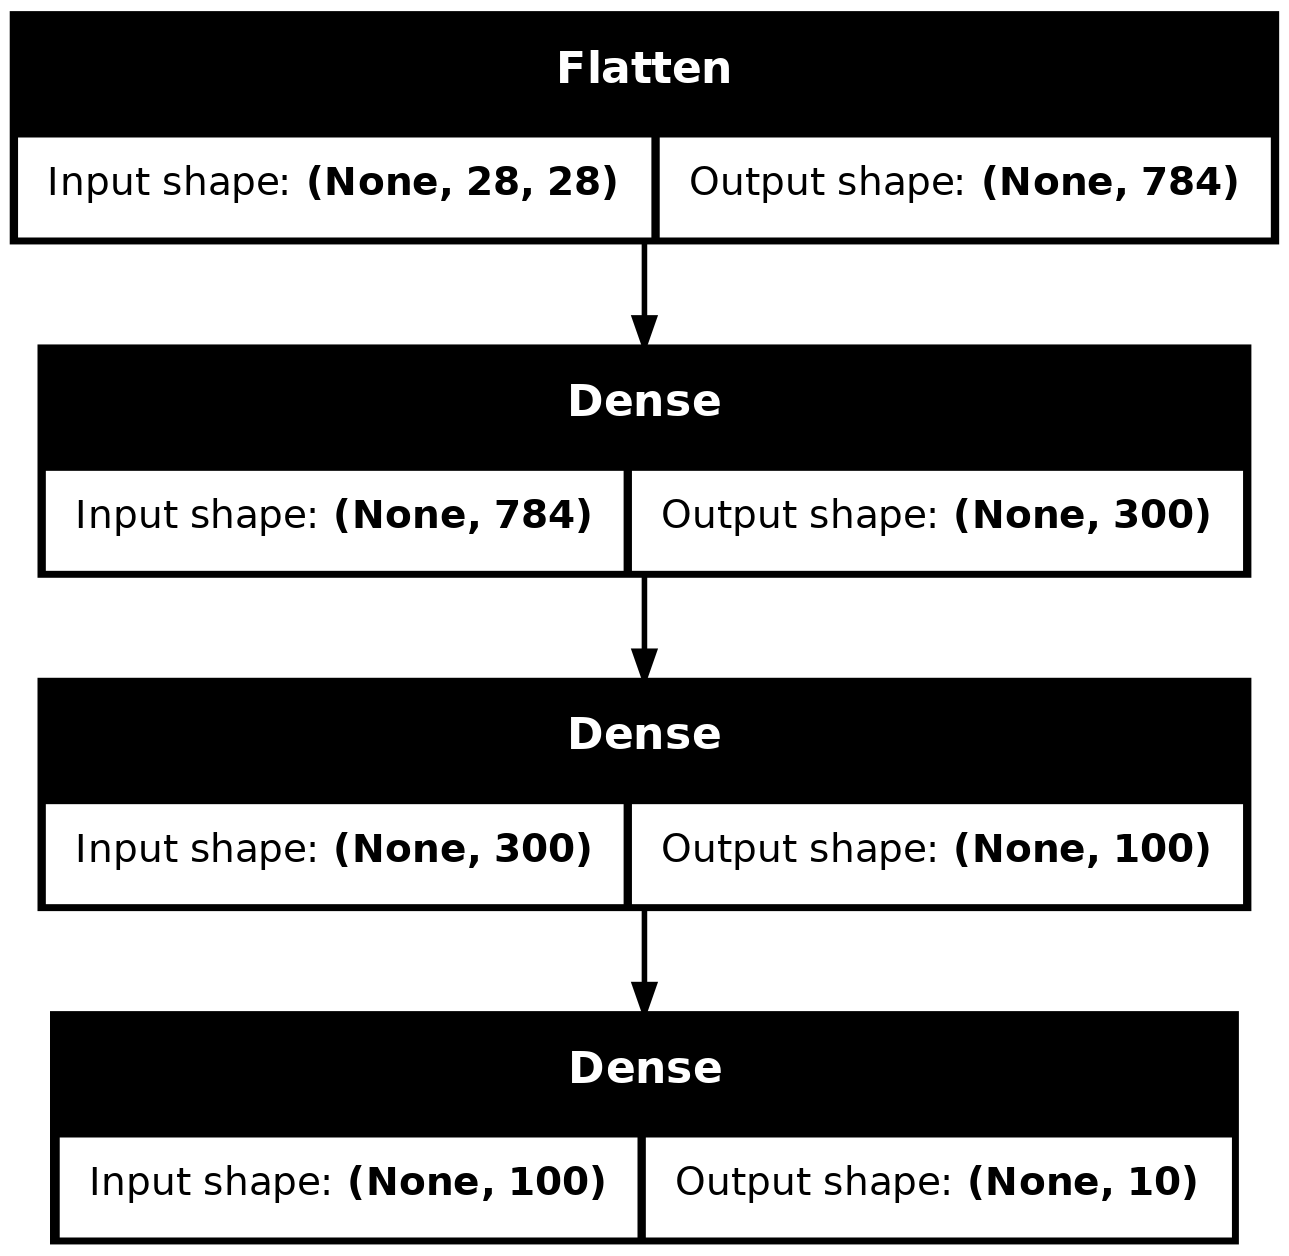

In [15]:
tf.keras.utils.plot_model(model,show_shapes=True) # In below image image None means batch size is none

In [16]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [17]:
hidden1 = model.layers[1]
hidden1.name

'dense'

In [18]:
model.get_layer('dense') is hidden1

True

In [19]:
# All the parameters of a layer can be accessed using its get_weights() and set_weights() methods.
weights, biases = hidden1.get_weights()

In [20]:
weights

array([[-0.0327842 ,  0.02013937, -0.01304394, ..., -0.07024561,
        -0.0528016 , -0.07206755],
       [-0.05324384, -0.03740997,  0.0276073 , ...,  0.02372433,
        -0.06470237,  0.001662  ],
       [-0.05701376, -0.02932214, -0.06290224, ..., -0.04228985,
        -0.03645484,  0.05219911],
       ...,
       [-0.05340394, -0.06280378, -0.04270665, ..., -0.05428466,
        -0.07048331, -0.00273167],
       [ 0.06297697, -0.06192464, -0.04656767, ...,  0.06101702,
         0.04221031, -0.06722157],
       [ 0.03913063, -0.0260509 ,  0.01201414, ...,  0.04619218,
        -0.05288717, -0.05625749]], shape=(784, 300), dtype=float32)

In [21]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [22]:
biases.shape

(300,)

### Compiling the model

In [23]:
# we call model's compile method to specify the loss function and optimizer.
model.compile(loss="sparse_categorical_crossentropy",
             optimizer="sgd",
             metrics=["accuracy"])

we use "sparse_categorical_crossentropy" because we have sparse labels (for each instance there is just a target class index, from 0 to 9 in this). use "categorical_crossentropy" when we have one hot vectors (0,0,0,0,1,0,0,0). for binary use "binary_crossentropy". optimizer, "sgd" means that we will train the model using stochastic gradient descent. we use metrics "accuracy" to measure its accuracy during training and evalution. 

In [24]:
# above cell code ie equal to below code
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy,
             optimizer=tf.keras.optimizers.SGD(),
             metrics=[tf.keras.metrics.sparse_categorical_accuracy])

In [28]:
# How to convert class id's to one-hot vector
tf.keras.utils.to_categorical([0, 5, 1, 0],num_classes=10)

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [29]:
# How to convert one-hot vectors to class ids
np.argmax(
    [[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
     [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
     [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]],
    axis=1
)

array([0, 5, 1, 0])

### Training and evaluating the model

In [30]:
history = model.fit(X_train,y_train,epochs=30,
                   validation_data=(X_val,y_val))

Epoch 1/30


2026-04-29 20:53:00.841596: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 172480000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 0.7189 - sparse_categorical_accuracy: 0.7645 - val_loss: 0.5094 - val_sparse_categorical_accuracy: 0.8300
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.4868 - sparse_categorical_accuracy: 0.8306 - val_loss: 0.4562 - val_sparse_categorical_accuracy: 0.8412
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 0.4416 - sparse_categorical_accuracy: 0.8465 - val_loss: 0.4321 - val_sparse_categorical_accuracy: 0.8458
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 0.4141 - sparse_categorical_accuracy: 0.8546 - val_loss: 0.4162 - val_sparse_categorical_accuracy: 0.8530
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 0.3937 - sparse_categorical_accuracy: 0.8616 - val_loss: 0.4046 - val_sparse_categorical_accuracy: 0.8538
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - loss: 0.3775 - sparse_categorical_accuracy: 0.8672 - val_loss: 0.3958 - val_sparse_categorical_accuracy: 0.85

Epoch 3/30 means 3rd epoch out of 30. 
(1 to 1719) /1719 means At each epoch during training, Keras displays the number of mini-batches processed. The batch size is 32 by default, and since the training set has 55,000 images, the model goes through 1,719 batches per epoch: 1,718 of size 32, and 1 of size 24.

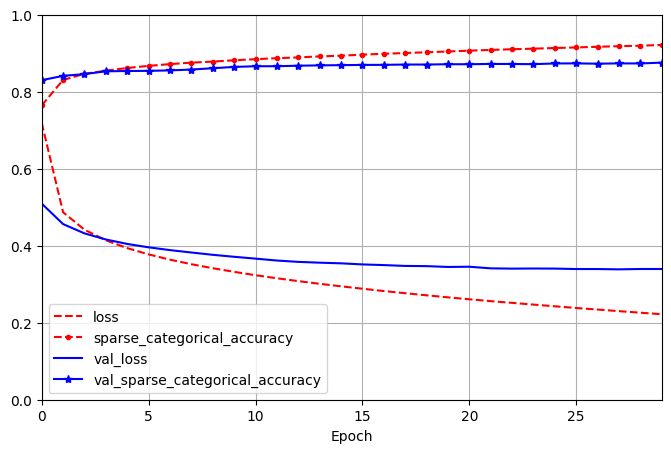

In [33]:
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
plt.legend(loc="lower left")
plt.show()

In [34]:
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3583 - sparse_categorical_accuracy: 0.8738


[0.3582615554332733, 0.8737999796867371]

### Using the model to make predictions

In [35]:
X_new = X_test[:3]

In [36]:
y_proba = model.predict(X_new)
y_proba

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step


array([[2.4199511e-05, 2.8838870e-06, 4.3321244e-05, 2.5292758e-05,
        7.6900534e-07, 2.4799663e-01, 2.5766831e-05, 2.6012972e-02,
        9.3320571e-04, 7.2493488e-01],
       [4.8553475e-06, 2.8677434e-08, 9.9961650e-01, 1.0261125e-08,
        3.6099224e-04, 3.2063838e-11, 1.7623492e-05, 8.2279680e-13,
        5.4164198e-09, 1.0784067e-12],
       [6.2096374e-06, 9.9999273e-01, 4.7426628e-08, 7.2302123e-07,
        2.7868941e-07, 1.0862515e-09, 6.6401000e-09, 1.6446539e-12,
        1.8570603e-10, 1.0644260e-11]], dtype=float32)

In [37]:
y_proba.round(2)

array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.25, 0.  , 0.03, 0.  , 0.72],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [38]:
y_pred = np.argmax(y_proba,axis=-1)
y_pred

array([9, 2, 1])

In [39]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

In [40]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

## Building a Regression MLP Using the Sequential API

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

In [5]:
housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [63]:
norm_layer = tf.keras.layers.Normalization(input_shape=X_train[0].shape) # it does the same thing as Scikit- Learn’s StandardScaler
# but it must be fitted to the training data using its adapt() method before you call the model’s fit() method.

/home/sureshsecond/venv/lib/python3.10/site-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [60]:
model = tf.keras.Sequential([
    normal_layer,
    tf.keras.layers.Dense(50,activation="relu"),
    tf.keras.layers.Dense(50,activation="relu"),
    tf.keras.layers.Dense(50,activation="relu"),
    tf.keras.layers.Dense(1) # output layer
])

In [61]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse",optimizer=optimizer,metrics=["RootMeanSquaredError"])

In [64]:
norm_layer.adapt(X_train) # layer learns the feature means and standard deviations in the training data when you call the adapt() method.

In [ ]:
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))

In [ ]:
mse_test, rmse_test = model.evaluate(X_test, y_test)

In [ ]:
rmse_test

In [ ]:
X_new = X_test[:3]
y_pred = model.predict(X_new)

### Building Complex Models Using the Functional API

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [8]:
normalization_layer = tf.keras.layers.Normalization()
h1_layer = tf.keras.layers.Dense(30,activation="relu")
h2_layer = tf.keras.layers.Dense(30,activation="relu")
concat_layer = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train[0].shape)
normalized = normalization_layer(input_)
hidden1 = h1_layer(normalized)
hidden2 = h2_layer(hidden1)
concat = concat_layer([normalized,hidden2])
ouput = output_layer(concat)

model = tf.keras.Model(inputs=[input_],outputs=[ouput])

In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 8)         │         17 │ input_layer_1[0]… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 30)        │        270 │ normalization_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 30)        │        930 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 38)        │          0 │ normalization_1[… │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         39 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,256 (4.91 KB)

 Trainable params: 1,239 (4.84 KB)

 Non-trainable params: 17 (72.00 B)

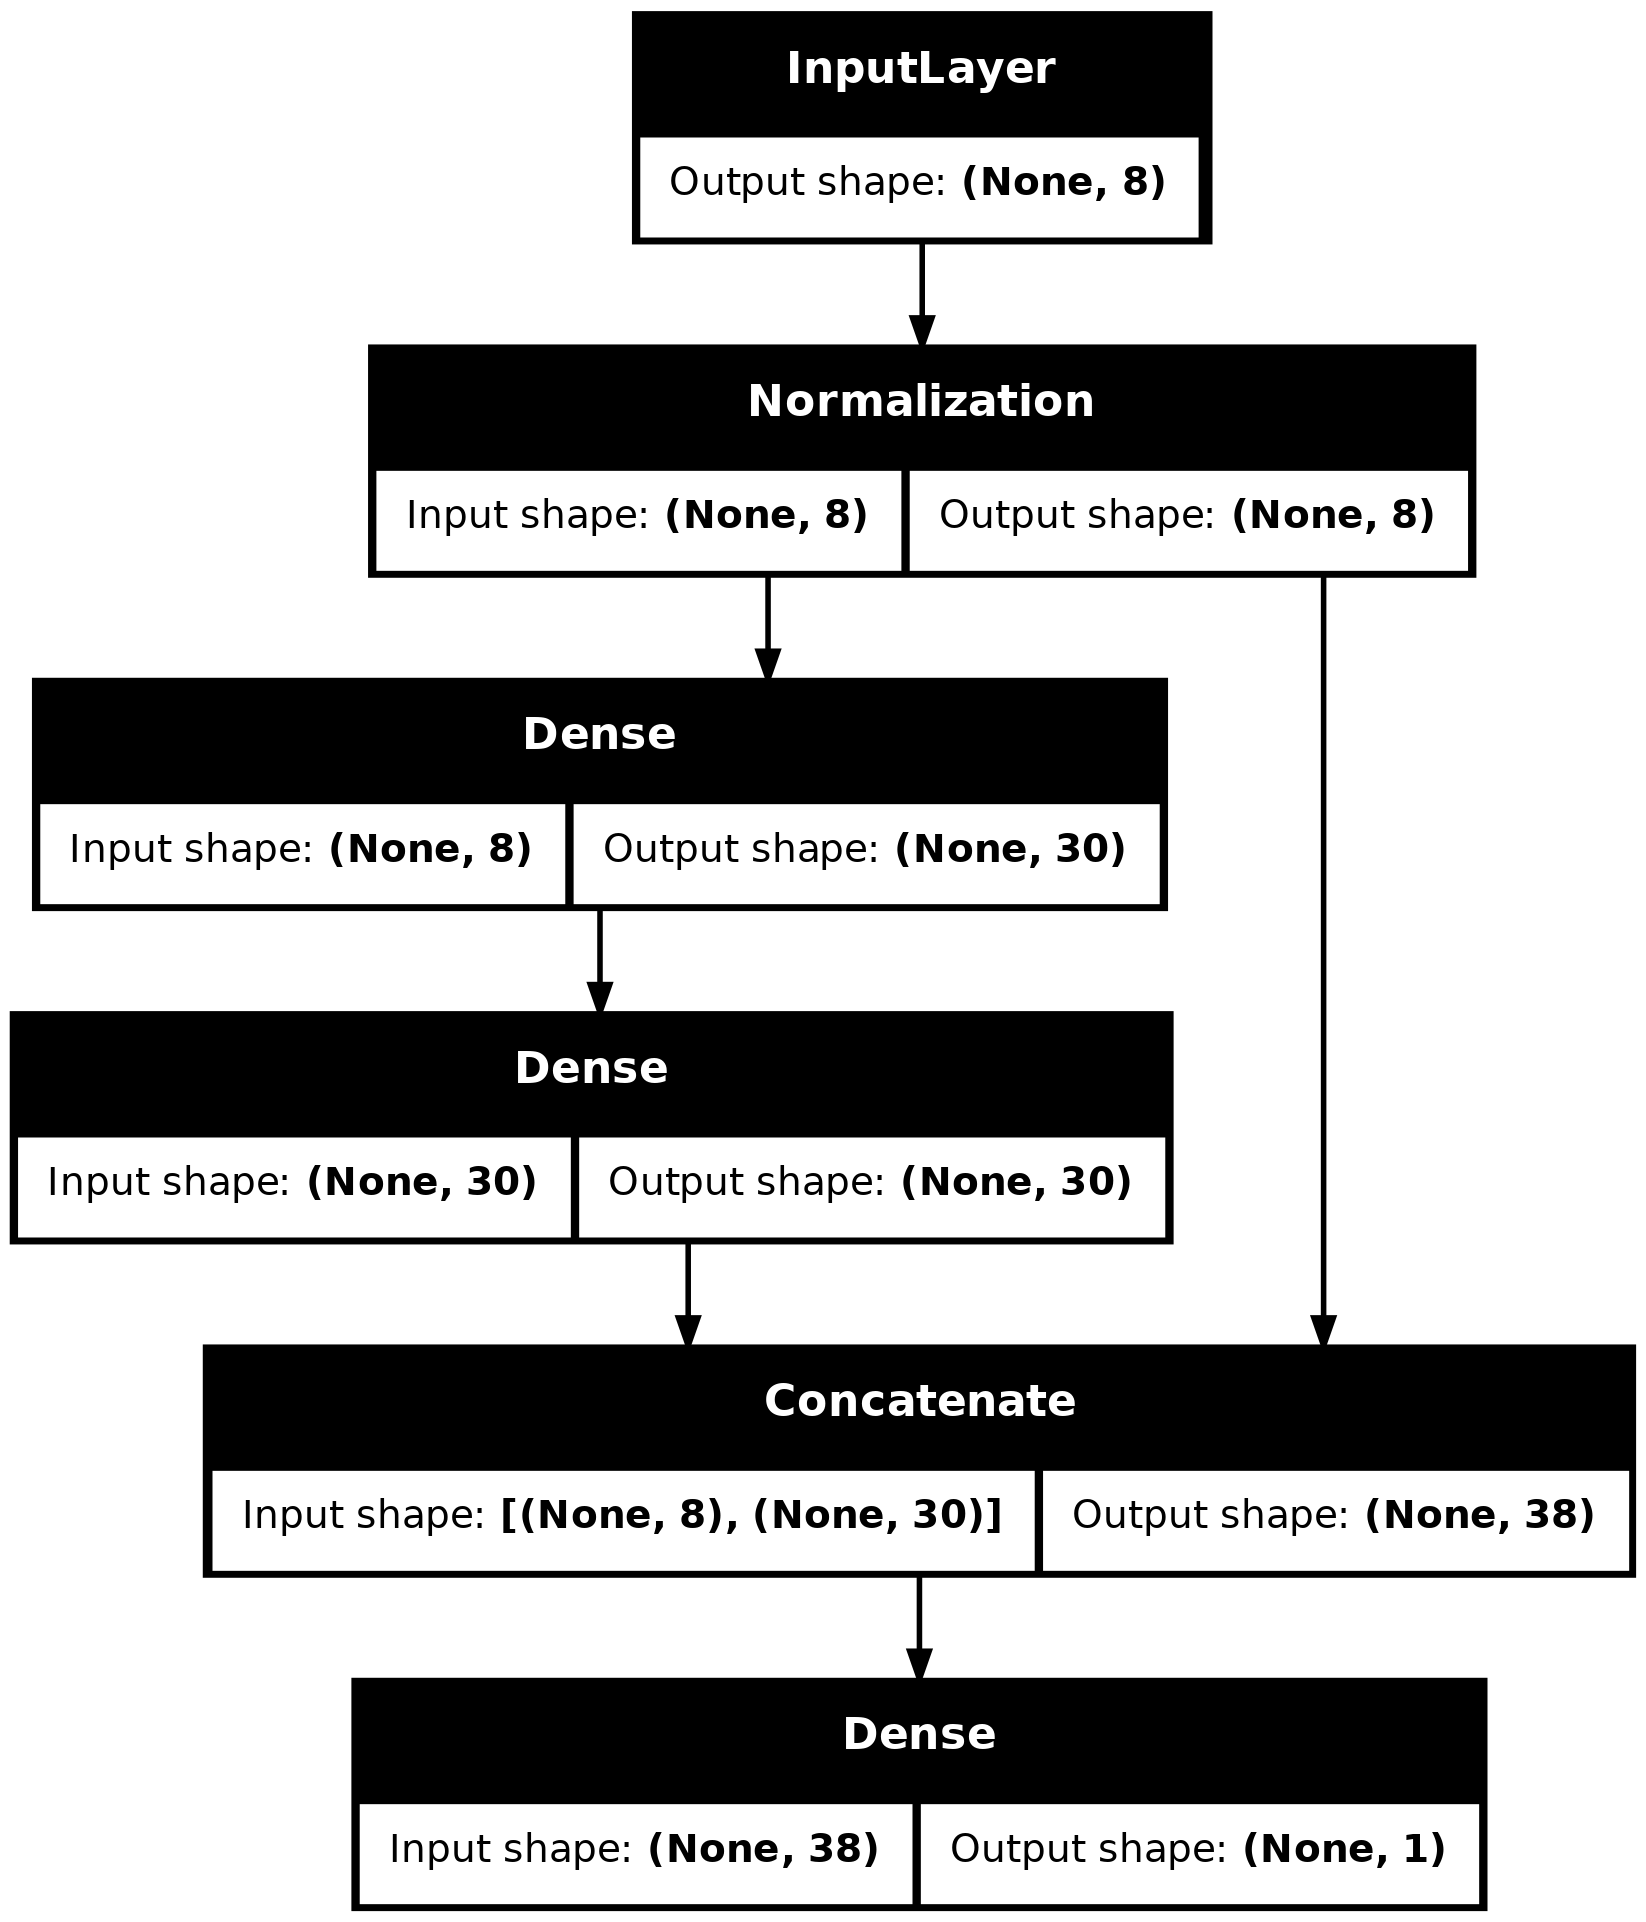

In [10]:
tf.keras.utils.plot_model(model,show_shapes=True)

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse",optimizer=optimizer, mertices=["RootMeanSquaredError"])
normalization_layer.adapt(X_train)
history = model.fit(X_train,y_train,epochs=20,
                   validation_data=(X_valid, y_valid))

In [ ]:
model.evaluate(X_test,y_test)

In [ ]:
y_pred = model.predict(X_new)